# AULE Computer Vision Challenge
## Solution, including the follow-up from the interview

This notebook holds the complete solution in one file: the source code, the reference image,
the tests and the recorded results are embedded in it.

**To run:** open it in Google Colab and choose **Runtime > Run all**. The first code cell unpacks
the project and installs any missing packages (this needs internet access). Outputs from a full
run are already saved in the notebook, so the results can also be read without running it.

**Contents**

*Part 1: the original challenge*

- 1.1 Port and marker detection, shared by all parts
- 1.2 Part A: rotation estimation
- 1.3 Part B: locating a crop, and moving the camera until the marker is visible
- 1.4 Part C: the view from 22.5 degrees to the right, 100 cm from the centre
- 1.5 Part D: returning to the front view at a constant 100 cm
- 1.6 Validation of the rendered images
- 1.7 Recorded benchmarks and optional checks
- 1.8 Design notes, assumptions and limitations

*Part 2: the follow-up. Parts B and D redone so that commanded motion is never trusted*

- 2.1 Part B: with zoom (subtask A), without zoom (subtask B), diagonal moves, and single-axis fixes
- 2.2 Part D: the camera pose found from the image at every step, converging to the front at 100 cm

**Switches** in the cell after the setup: `FULL_RUNS` recomputes the randomised studies in Part 2
instead of loading their recorded results, `RUN_FULL_ROTATION_SWEEP` reruns the Part A sweep, and
`RUN_TESTS` runs the regression tests.

**Scope:** every experiment uses simulated cameras built from the supplied drawing. Real cameras and
motion hardware have not been tested.

In [1]:
# Setup: unpacks the embedded project (source code, reference image, tests, recorded
# results) and installs any missing packages. No Drive mount or download is needed.
import base64, hashlib, importlib.util, io, os, shutil, subprocess, sys, zipfile
from pathlib import Path
IN_COLAB = importlib.util.find_spec("google.colab") is not None
WORK = Path(os.environ.get("AULECV_DEMO_WORKDIR",
                           "/content/aule_solution" if IN_COLAB else str(Path.cwd() / "aule_solution"))).resolve()
PROJECT_ROOT = WORK / "AULE_ComputerVisionChallenge"
if PROJECT_ROOT.exists():
    shutil.rmtree(PROJECT_ROOT)
PROJECT_ROOT.mkdir(parents=True)
PAYLOAD_B64 = '...'
payload = base64.b64decode(PAYLOAD_B64)
assert hashlib.sha256(payload).hexdigest() == '1b91acb0de506fbcf818862ec02cec7851e0176be0d8d2c423426f28426931f8', "embedded project is damaged"
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    for item in archive.infolist():
        if not (PROJECT_ROOT / item.filename).resolve().is_relative_to(PROJECT_ROOT):
            raise ValueError("invalid path in embedded project")
    archive.extractall(PROJECT_ROOT)
required = {"numpy": "numpy>=1.23", "cv2": "opencv-python-headless>=4.6", "pandas": "pandas>=1.5",
            "matplotlib": "matplotlib>=3.7", "imageio": "imageio>=2.25", "PIL": "pillow>=9.0"}
missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
if importlib.util.find_spec("matplotlib"):
    from importlib.metadata import version
    if tuple(map(int, version("matplotlib").split(".")[:2])) < (3, 7):
        missing.append("matplotlib>=3.7")
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
os.environ["AULECV_PROJECT_ROOT"] = str(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
for name in list(sys.modules):          # a second "Run all" must load this copy
    if name == "aulecv" or name.startswith("aulecv."):
        del sys.modules[name]
import numpy as np, cv2, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display
from aulecv import config as C, detect, rotation, navigation, camera, viz, closed_loop as cl
from aulecv import io as aio
%matplotlib inline
plt.rcParams["figure.dpi"] = 105
np.set_printoptions(precision=4, suppress=True)
np.random.seed(C.RANDOM_SEED)
OUT = aio.ensure_output_dirs()
reference = aio.load_reference()
ref_det = detect.detect_port(reference)
assert ref_det.marker_found
print("Project ready | Python", sys.version.split()[0], "| OpenCV", cv2.__version__, "| NumPy", np.__version__)


Project ready | Python 3.14.3 | OpenCV 4.13.0 | NumPy 2.4.3


In [2]:
# Optional switches. With the defaults, Run all takes a few minutes.
FULL_RUNS = False                 # True: recompute the randomised many-run studies in Part 2 (several minutes)
RUN_FULL_ROTATION_SWEEP = False   # True: rerun the Part A check on all 360 whole-degree angles
RUN_TESTS = False                 # True: run the project's regression tests (section 1.7)

# Part 1: the original challenge

The four tasks as set: rotation, crop localisation and navigation, the 22.5 degree view, and the
return to the front. Source code is in `src/aulecv/`; each section names the module it uses.

## 1.1 Port and marker detection
The outer quad supplies plane geometry; the circular marker supplies orientation.
Background separation and contours identify the quad. Border thickness sets morphology
scale. Marker candidates are checked with shape and centre agreement. The corner nearest
the marker defines canonical ordering. Confidence is heuristic, not a probability.
Source: `src/aulecv/detect.py`; thresholds: `config.py`.

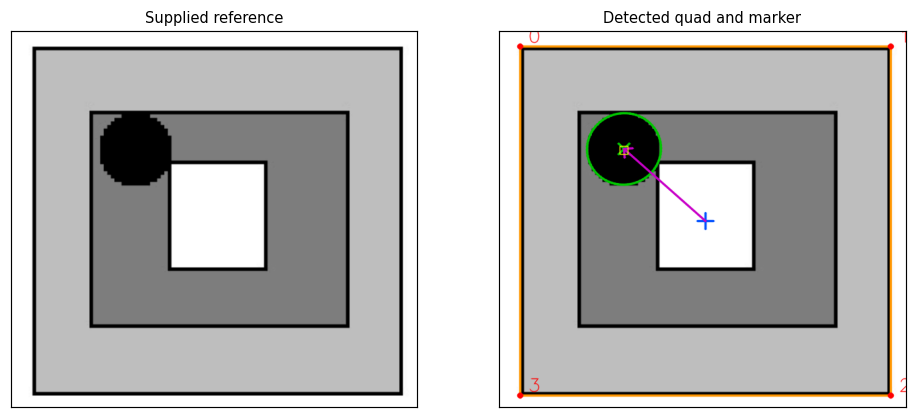

Marker centre: [185.016 176.499] | confidence: 0.9385


In [3]:
det=ref_det
fig,axes=plt.subplots(1,2,figsize=(11,5))
viz.show(reference,'Supplied reference',ax=axes[0])
viz.show(viz.draw_detection(reference,det),'Detected quad and marker',ax=axes[1])
fig.savefig(aio.output_path('detection','reference_detection.png'),bbox_inches='tight')
plt.show()
print('Marker centre:',np.round(det.marker_center,3),'| confidence:',round(det.confidence,4))

## 1.2 Part A: rotation (the marker picks the quarter turn, the edges refine it)
A square alone supplies rotation modulo 90 degrees. The centre-to-marker vector selects
the quarter turn; edges refine the angle. In image coordinates (x right, y down), OpenCV's
positive rotation appears counter-clockwise, so $a=(\theta_0-\theta_1)\bmod 360$.
Wrapped error handles the 0/360 boundary. Source: `rotation.py`.
`DEMO_ANGLE` controls the generated input; the estimator receives only image data and reference detection.

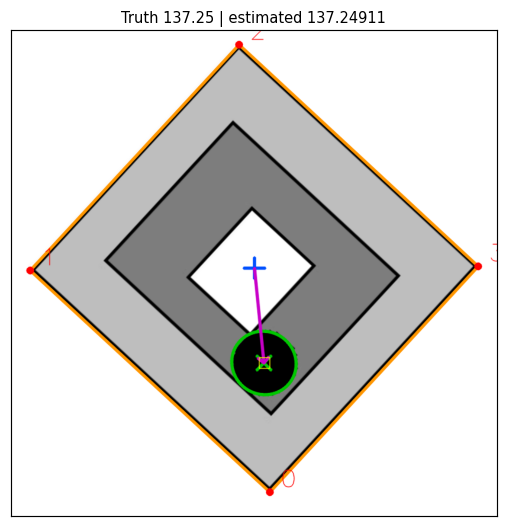

Wrapped error: -0.0008947320633012623 degrees


In [4]:
DEMO_ANGLE=137.25
rotated=rotation.rotate_image(reference,DEMO_ANGLE)
est=rotation.estimate_rotation(rotated,ref_det)
viz.show(viz.draw_detection(rotated,est.detection),f'Truth {DEMO_ANGLE} | estimated {est.angle_deg:.5f}')
plt.show()
print('Wrapped error:',rotation.angular_error(est.angle_deg,DEMO_ANGLE),'degrees')
assert est.status=='ok'

In [5]:
ANGLES = [0.0, 7.5, 23.0, 45.0, 90.0, 137.25, 180.0, 222.5, 270.0, 313.7, 359.0]

rows, panels, titles = [], [], []
for a in ANGLES:
    img = rotation.rotate_image(reference, a)
    est = rotation.estimate_rotation(img, ref_det)
    rows.append({
        "true_deg": a,
        "estimated_deg": round(est.angle_deg, 4),
        "error_deg": round(rotation.angular_error(est.angle_deg, a), 4),
        "marker_only_deg": round(est.marker_angle_deg, 4),
        "marker_only_err": round(rotation.angular_error(est.marker_angle_deg, a), 4),
        "edge_mod90_deg": round(est.edge_angle_mod90_deg, 4),
        "refined": est.refined,
        "residual_deg": round(est.residual_deg, 4),
        "confidence": round(est.confidence, 3),
        "status": est.status,
    })
    panels.append(viz.draw_detection(img, est.detection, label_corners=False))
    titles.append("true {:g} deg\nest {:.3f} deg".format(a, est.angle_deg))

results = pd.DataFrame(rows)
display(results)
print("\nMEASURED on these {} angles:".format(len(ANGLES)))
print("  fused      MAE {:.4f} deg   max |err| {:.4f} deg"
      .format(results['error_deg'].abs().mean(), results['error_deg'].abs().max()))
print("  marker only MAE {:.4f} deg   max |err| {:.4f} deg"
      .format(results['marker_only_err'].abs().mean(), results['marker_only_err'].abs().max()))

,true_deg,estimated_deg,error_deg,marker_only_deg,marker_only_err,edge_mod90_deg,refined,residual_deg,confidence,status
0,0.00,0.0000,0.0000,0.0000,0.0000,0.0000,True,0.0000,0.938,ok
1,7.50,7.5010,0.0010,7.4999,-0.0001,7.5010,True,0.0011,0.938,ok
2,23.00,22.9998,-0.0002,23.0090,0.0090,22.9998,True,0.0092,0.938,ok
3,45.00,45.0000,0.0000,45.0555,0.0555,45.0000,True,0.0555,0.938,ok
4,90.00,90.0000,-0.0000,89.9963,-0.0037,90.0000,True,0.0037,0.907,ok
5,137.25,137.2491,-0.0009,137.2474,-0.0026,47.2491,True,0.0017,0.938,ok
6,180.00,180.0000,-0.0000,179.9351,-0.0649,90.0000,True,0.0649,0.921,ok
7,222.50,222.5011,0.0011,222.5377,0.0377,42.5011,True,0.0366,0.927,ok
8,270.00,270.0000,-0.0000,269.9290,-0.0710,90.0000,True,0.0710,0.920,ok
9,313.70,313.7018,0.0018,313.6816,-0.0184,43.7018,True,0.0201,0.908,ok



MEASURED on these 11 angles:
  fused      MAE 0.0008 deg   max |err| 0.0043 deg
  marker only MAE 0.0239 deg   max |err| 0.0710 deg


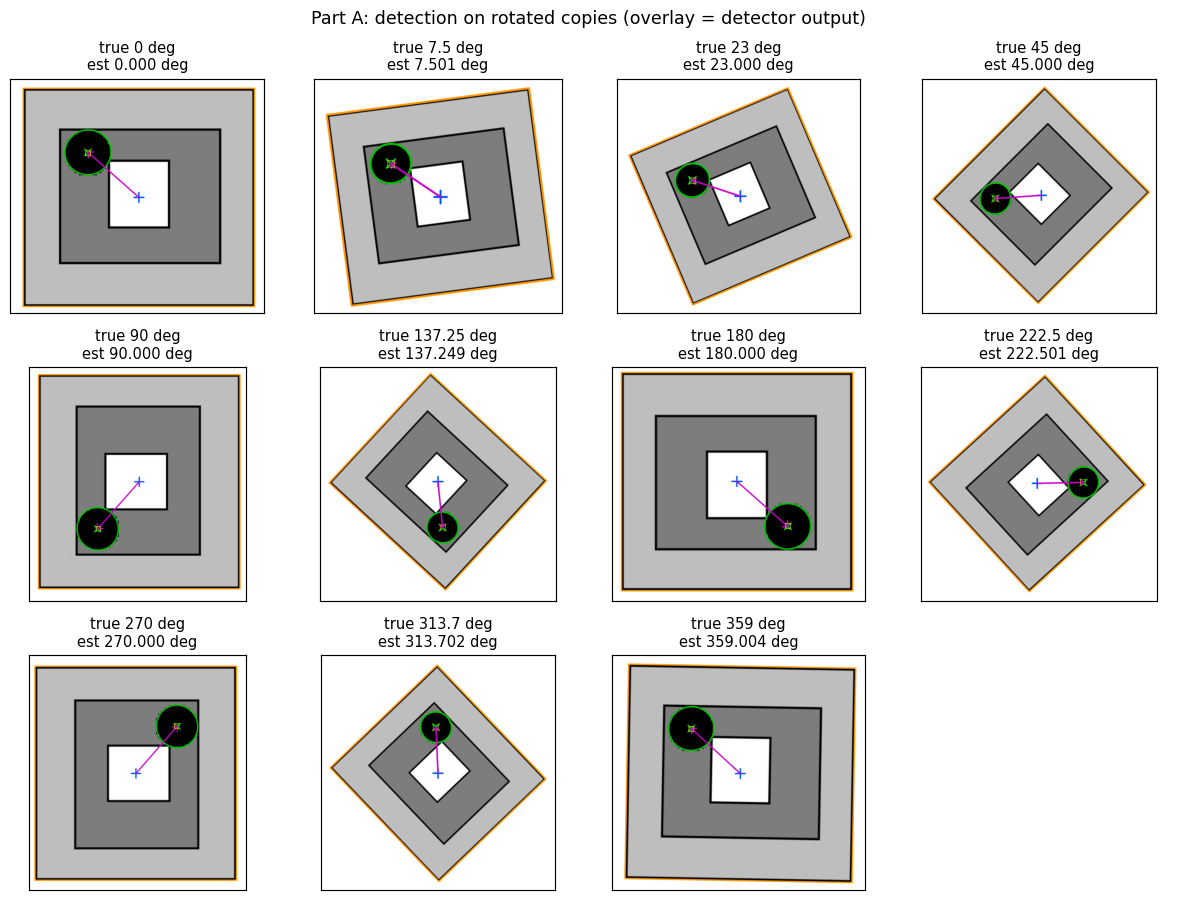

In [6]:
fig = viz.grid(panels, titles, cols=4, figsize_per=2.9,
               suptitle="Part A: detection on rotated copies (overlay = detector output)")
fig.savefig(aio.output_path("rotation_tests", "requested_angles.png"),
            bbox_inches="tight", dpi=110)
plt.show()

In [7]:
assert (results['status']=='ok').all()
print('Fresh sample MAE:',results['error_deg'].abs().mean(),'degrees')

Fresh sample MAE: 0.0008454545454545454 degrees


status      : marker_missing
angle_deg   : nan
confidence  : 0.0
note        : the circular marker was not localised; the square alone only determines the angle modulo 90 deg


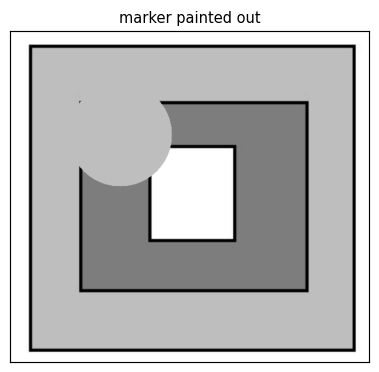

In [8]:
painted = reference.copy()
cv2.circle(painted, tuple(np.round(ref_det.marker_center).astype(int)),
           int(round(ref_det.marker_radius_px * 1.6)), (190, 190, 190), -1)
est = rotation.estimate_rotation(rotation.rotate_image(painted, 33.0), ref_det)
print("status      :", est.status)
print("angle_deg   :", est.angle_deg)
print("confidence  :", est.confidence)
for n in est.notes:
    print("note        :", n)
viz.show(painted, "marker painted out", figsize=(4.4, 4.1)); plt.show()

## 1.3 Part B: crop localisation, movement and refusal cases
Normalised correlation matches a same-scale crop. A high best score is insufficient:
flat texture, broad plateaus and competing peaks make location ambiguous. Uncertain
crops yield no deterministic route. Source: `navigation.py`.
**Convention:** RIGHT is +image x and DOWN is +image y. Commands translate the camera
parallel to the plane at fixed orientation and scale. The view window follows that
motion; image content moves oppositely. Pixel-to-centimetre conversion is approximate
because the reference is schematic. The example verifies arrival of the whole marker.

In [9]:
WIN = (400, 380, 200, 170)
crop = navigation.extract_crop(reference, *WIN)
loc = navigation.localize_crop(crop, reference)
plan = navigation.plan_crop_movements(loc, ref_det, reference.shape)

print("localisation")
print("  status            :", loc.status)
print("  found at          :", (loc.x, loc.y), " (true {})".format(WIN[:2]))
print("  peak score        : {:.6f}".format(loc.score))
print("  second peak       : {:.6f}  (ratio {:.4f})".format(loc.second_peak, loc.second_peak_ratio))
print("  plateau extent    : {} px".format(loc.plateau_extent_px))
print("  per-axis uncert.  : {} px".format(tuple(round(v, 2) for v in loc.uncertainty_px)))
print("  reason            :", loc.reasons[0])
print()
print("plan")
print("  status            :", plan.status)
print("  goal              :", plan.goal)
print("  start window      :", plan.start_window)
print("  target window     :", plan.target_window)
print("  step size         : {:.1f} px".format(plan.step_px))
print("  total translation : dx {:+.1f} px ({:+.2f} cm),  dy {:+.1f} px ({:+.2f} cm)"
      .format(plan.total_px[0], plan.total_cm[0], plan.total_px[1], plan.total_cm[1]))
print("  steps issued      : {}   (optimal ceil(d/step) = {})".format(plan.n_steps, plan.optimal_steps))
print("  note              :", plan.reasons[0])
print()
print("first 5 and last 5 commands:")
for cmd in plan.commands[:5]:
    print("  " + cmd.describe())
print("  ...")
for cmd in plan.commands[-5:]:
    print("  " + cmd.describe())

localisation
  status            : ok
  found at          : (400, 380)  (true (400, 380))
  peak score        : 0.999999
  second peak       : 0.686721  (ratio 0.6867)
  plateau extent    : (1, 1) px
  per-axis uncert.  : (0.0, 0.0) px
  reason            : unique, sharply-peaked match

plan
  status            : ok
  goal              : full_disk
  start window      : (400, 380, 200, 170)
  target window     : (125, 116, 200, 170)
  step size         : 8.5 px
  total translation : dx -275.0 px (-20.00 cm),  dy -264.0 px (-20.39 cm)
  steps issued      : 65   (optimal ceil(d/step) = 65)
  note              : camera translation parallel to the port plane, under the frontal pinhole model

first 5 and last 5 commands:
  step   1: move camera LEFT     8.5 px  ( 0.62 cm)  -> window (x= 392, y= 380)
  step   2: move camera LEFT     8.5 px  ( 0.62 cm)  -> window (x= 383, y= 380)
  step   3: move camera LEFT     8.5 px  ( 0.62 cm)  -> window (x= 374, y= 380)
  step   4: move camera LEFT     8.

In [10]:
frames = navigation.simulate_crop_navigation(reference, plan)
final_win = frames[-1]["window"]
print("final window            :", final_win)
print("marker fully visible?   :", navigation.marker_visible(final_win, ref_det, plan.goal))
print("frames rendered         :", len(frames), "(each cut fresh from the reference)")

cmds = pd.DataFrame([{"step": c.step, "direction": c.direction,
                      "dx_px": c.dx_px, "dy_px": c.dy_px,
                      "distance_px": c.distance_px, "distance_cm": round(c.distance_cm, 4),
                      "window_x": c.window_after[0], "window_y": c.window_after[1]}
                     for c in plan.commands])
cmds.to_csv(aio.output_path("crop_navigation", "commands.csv"), index=False)
display(cmds.head(8))

final window            : (125, 116, 200, 170)
marker fully visible?   : True
frames rendered         : 66 (each cut fresh from the reference)


,step,direction,dx_px,dy_px,distance_px,distance_cm,window_x,window_y
0,1,LEFT,-8.5,0.0,8.5,0.6182,392,380
1,2,LEFT,-8.5,0.0,8.5,0.6182,383,380
2,3,LEFT,-8.5,0.0,8.5,0.6182,374,380
3,4,LEFT,-8.5,0.0,8.5,0.6182,366,380
4,5,LEFT,-8.5,0.0,8.5,0.6182,358,380
5,6,LEFT,-8.5,0.0,8.5,0.6182,349,380
6,7,LEFT,-8.5,0.0,8.5,0.6182,340,380
7,8,LEFT,-8.5,0.0,8.5,0.6182,332,380


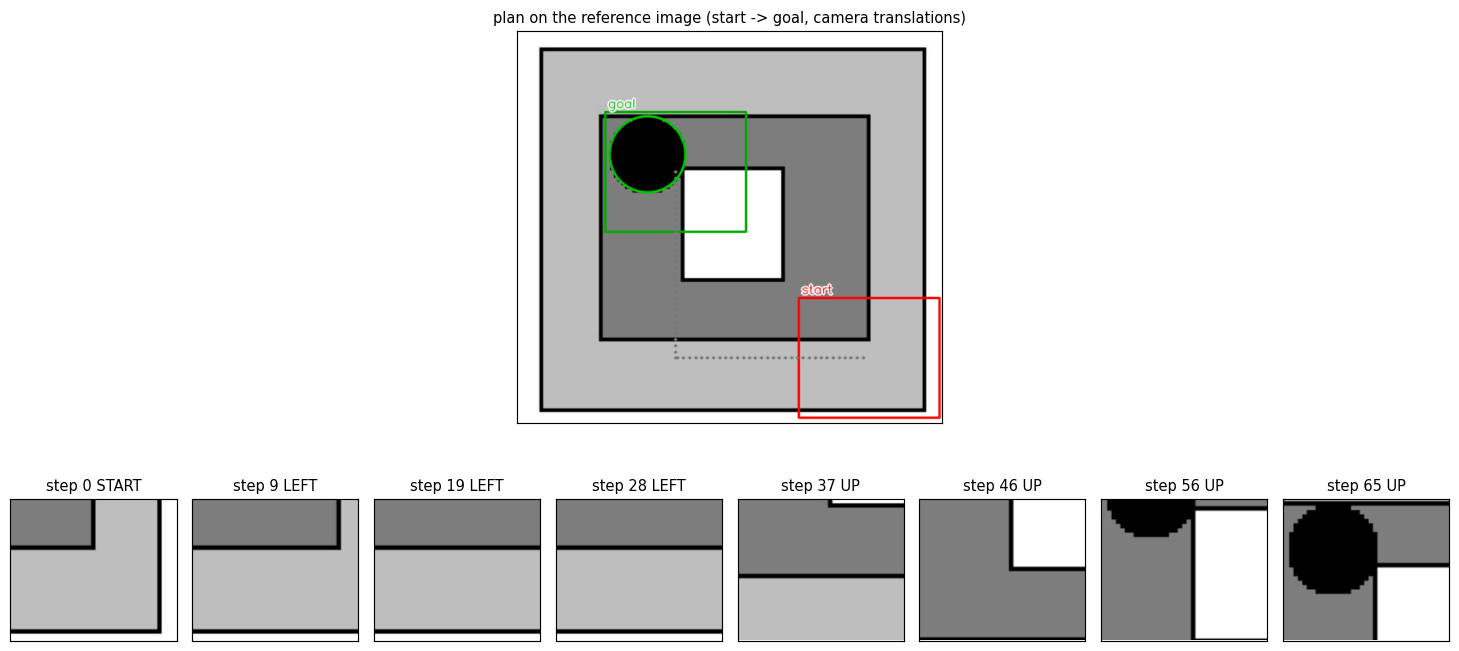

In [11]:
fig = viz.navigation_figure(reference, ref_det, plan, max_panels=8)
fig.savefig(aio.output_path("crop_navigation", "plan_overview.png"),
            bbox_inches="tight", dpi=110)
plt.show()

In [12]:
assert navigation.marker_visible(final_win,ref_det,plan.goal)
refusals=[]
for name,win in [('edge strip',(200,20,120,16)),('uniform patch',(4,4,18,18))]:
    l=navigation.localize_crop(navigation.extract_crop(reference,*win),reference)
    p=navigation.plan_crop_movements(l,ref_det,reference.shape)
    refusals.append({'input':name,'status':l.status,'commands':p.n_steps,'reason':'; '.join(l.reasons)})
    assert l.status!='ok' and p.n_steps==0
display(pd.DataFrame(refusals))

,input,status,commands,reason
0,edge strip,ambiguous,0,419 positions have indistinguishable match sco...
1,uniform patch,featureless,0,crop grey-level std 0.00 < 3.00: no structure ...


### 1.3.1 Extension: look again and re-plan
A fixed plan assumes exact motion. The feedback runner uses returned frames to search,
re-localise and replan under one budget. This simulated test uses 100% and 60% motion.
A small crop under `auto` can use the marker-centre goal. Bounded search can fail on
uninformative views; this does not demonstrate hardware feedback control.

In [13]:
def simulated_camera(start_window, gain=1.0):
    """Feedback harness: the algorithm sees frames, never absolute coordinates."""
    H, W = reference.shape[:2]
    x, y, w, h = [int(v) for v in start_window]
    state = {"x": x, "y": y, "w": w, "h": h, "positions": [(x, y)]}

    def move_and_capture(dx, dy):
        state["x"] = int(np.clip(round(state["x"] + gain * dx), 0, W - w))
        state["y"] = int(np.clip(round(state["y"] + gain * dy), 0, H - h))
        state["positions"].append((state["x"], state["y"]))
        return navigation.extract_crop(reference, state["x"], state["y"], w, h)

    initial = navigation.extract_crop(reference, x, y, w, h)
    return initial, move_and_capture, state



START=(500,250,90,90)
# End-to-end execution: verify the marker from returned frames.
feedback_rows = []
for gain in (1.0, 0.6):
    initial, capture, state = simulated_camera(START, gain=gain)
    result = navigation.navigate_until_visible(initial, reference, ref_det, capture)
    actual_window = (state["x"], state["y"], state["w"], state["h"])
    assert result["status"] == "visible", result["reason"]
    assert result["window"] == actual_window
    assert navigation.marker_visible(actual_window, ref_det, result["goal"])
    assert result["steps_taken"] == len(state["positions"]) - 1
    feedback_rows.append({"motion_gain": gain, "status": result["status"],
                          "steps": result["steps_taken"],
                          "search_steps": result["steps_explored"],
                          "goal": result["goal"], "window": actual_window})
feedback = pd.DataFrame(feedback_rows)
display(feedback)
print("Arrival verified even when the camera only moves 60% of each request.")
feedback.to_csv(aio.output_path("crop_navigation", "feedback_navigation.csv"), index=False)

,motion_gain,status,steps,search_steps,goal,window
0,1.0,visible,95,57,marker_centre,"(151, 145, 90, 90)"
1,0.6,visible,155,107,marker_centre,"(178, 172, 90, 90)"


Arrival verified even when the camera only moves 60% of each request.


## 1.4 Part C: the view at 22.5 degrees
Map raster corners to a 40 x 40 cm plane with $G$. A pinhole camera is 100 cm from the
centre and looks at it: $H=K[r_1\ r_2\ t]G$.
The drawing's pixel proportions conflict with the stated square. The primary model
preserves the 40 cm geometry with square camera pixels. The secondary image-faithful
model preserves the raw frontal raster with non-square camera pixels. Only the outer
quad is geometrically validated. Focal length is chosen display scale under this model,
not measured calibration. Source: `camera.py`.

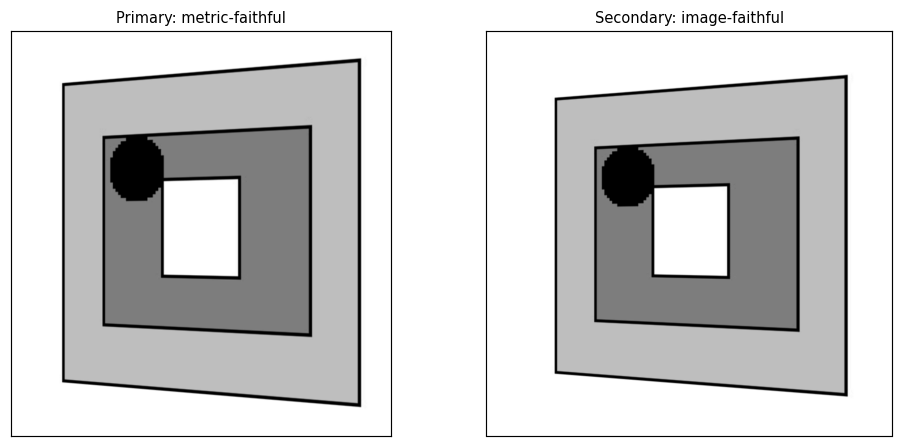

In [14]:
geom=camera.PortGeometry.from_detection(ref_det,reference.shape)
thetas=camera.generate_return_sequence(C.PART_C_ANGLE_DEG,C.PART_D_STEP_DEG)
renderA=camera.make_renderer(geom,thetas,'metric')
renderB=camera.make_renderer(geom,thetas,'image_faithful')
view_A=renderA.render(reference,C.PART_C_ANGLE_DEG)
view_B=renderB.render(reference,C.PART_C_ANGLE_DEG)
q_proj=renderA.project_port_corners(C.PART_C_ANGLE_DEG)
fig,axes=plt.subplots(1,2,figsize=(11,5))
viz.show(view_A,'Primary: metric-faithful',ax=axes[0])
viz.show(view_B,'Secondary: image-faithful',ax=axes[1])
fig.savefig(aio.output_path('homography','project_models.png'),bbox_inches='tight')
plt.show()

In [15]:
depths = camera.predicted_edge_depths_cm(C.PART_C_ANGLE_DEG, geom.side_cm, geom.distance_cm)
pred = camera.predicted_edge_height_ratio(C.PART_C_ANGLE_DEG, geom.side_cm, geom.distance_cm)
print("CLOSED FORM at theta = 22.5 deg")
print("  depth of the +X (right, near) edge : {:.6f} cm".format(depths["right_near_cm"]))
print("  depth of the -X (left,  far)  edge : {:.6f} cm".format(depths["left_far_cm"]))
print("  predicted near/far height ratio    : {:.6f}".format(pred))
print()

meas_proj = camera.measure_edge_height_ratio(q_proj)
print("(a) MEASURED ON THE PROJECTION (project the corners through H_A)")
print("  right edge {:.4f} px, left edge {:.4f} px, ratio {:.6f}, right taller: {}"
      .format(meas_proj["right_px"], meas_proj["left_px"], meas_proj["ratio"],
              meas_proj["right_is_taller"]))
print("  relative error vs closed form : {:.3e}".format(abs(meas_proj["ratio"] / pred - 1)))
print()

det_A = detect.detect_port(view_A)
meas_img = camera.measure_edge_height_ratio(det_A.quad)
print("(b) MEASURED ON THE RENDERED IMAGE (re-run the detector on the pixels)")
print("  detector confidence           : {:.4f}".format(det_A.confidence))
print("  re-detected quad:"); print("   ", np.round(det_A.quad, 2).tolist())
print("  right edge {:.4f} px, left edge {:.4f} px, ratio {:.6f}, right taller: {}"
      .format(meas_img["right_px"], meas_img["left_px"], meas_img["ratio"],
              meas_img["right_is_taller"]))
print("  relative error vs closed form : {:.3e}".format(abs(meas_img["ratio"] / pred - 1)))
print("  corner disagreement vs the projected quad: max {:.3f} px"
      .format(float(np.linalg.norm(det_A.quad - q_proj, axis=1).max())))

CLOSED FORM at theta = 22.5 deg
  depth of the +X (right, near) edge : 92.346331 cm
  depth of the -X (left,  far)  edge : 107.653669 cm
  predicted near/far height ratio    : 1.165760

(a) MEASURED ON THE PROJECTION (project the corners through H_A)
  right edge 577.9983 px, left edge 495.8124 px, ratio 1.165760, right taller: True
  relative error vs closed form : 8.882e-16

(b) MEASURED ON THE RENDERED IMAGE (re-run the detector on the pixels)
  detector confidence           : 0.8382
  re-detected quad:
    [[84.0, 87.19], [581.0, 45.92], [581.0, 624.65], [84.0, 583.44]]
  right edge 578.7357 px, left edge 496.2519 px, ratio 1.166214, right taller: True
  relative error vs closed form : 3.891e-04
  corner disagreement vs the projected quad: max 0.972 px


## 1.5 Part D: return along an orbit
$C(\theta)=(100\sin\theta,0,-100\cos\theta)$ cm preserves the 100 cm radius.
A chord cuts inside the circle. Every commanded pose points towards the centre.
Every frame is rendered from the original raster, avoiding accumulated interpolation
blur. This is an open-loop geometric trajectory, distinct from Part B feedback.

In [16]:
frames_A=[renderA.render(reference,float(t)) for t in thetas]
frames_B=[renderB.render(reference,float(t)) for t in thetas]
steps=pd.DataFrame(camera.return_sequence_table(thetas,C.CAMERA_DISTANCE_CM))
display(steps.round(5))
error=(steps.radius_cm-C.CAMERA_DISTANCE_CM).abs().max()
print('Maximum commanded radius error:',error,'cm')
assert error<C.POSE_RADIUS_TOL_CM
print('Chord alternative:',camera.arc_and_chord_cm(C.PART_C_ANGLE_DEG,C.CAMERA_DISTANCE_CM))

,step,theta_deg,Cx_cm,Cy_cm,Cz_cm,radius_cm,arc_cm,chord_cm
0,0,22.5,38.26834,0.0,-92.38795,100.0,0.00000,0.00000
1,1,20.0,34.20201,0.0,-93.96926,100.0,4.36332,4.36298
2,2,17.5,30.07058,0.0,-95.37170,100.0,4.36332,4.36298
3,3,15.0,25.88190,0.0,-96.59258,100.0,4.36332,4.36298
4,4,12.5,21.64396,0.0,-97.62960,100.0,4.36332,4.36298
5,5,10.0,17.36482,0.0,-98.48078,100.0,4.36332,4.36298
6,6,7.5,13.05262,0.0,-99.14449,100.0,4.36332,4.36298
7,7,5.0,8.71557,0.0,-99.61947,100.0,4.36332,4.36298
8,8,2.5,4.36194,0.0,-99.90482,100.0,4.36332,4.36298
9,9,0.0,0.00000,0.0,-100.00000,100.0,4.36332,4.36298


Maximum commanded radius error: 1.4210854715202004e-14 cm
Chord alternative: {'arc_cm': 39.269908169872416, 'chord_cm': 39.01806440322565, 'chord_midpoint_radius_cm': 98.07852804032305}


wrote outputs\camera_return.gif (340.8 KB)
wrote outputs\camera_return\camera_return_image_faithful.gif (337.8 KB)
(both loop back and forth so the sweep is visible either way round)


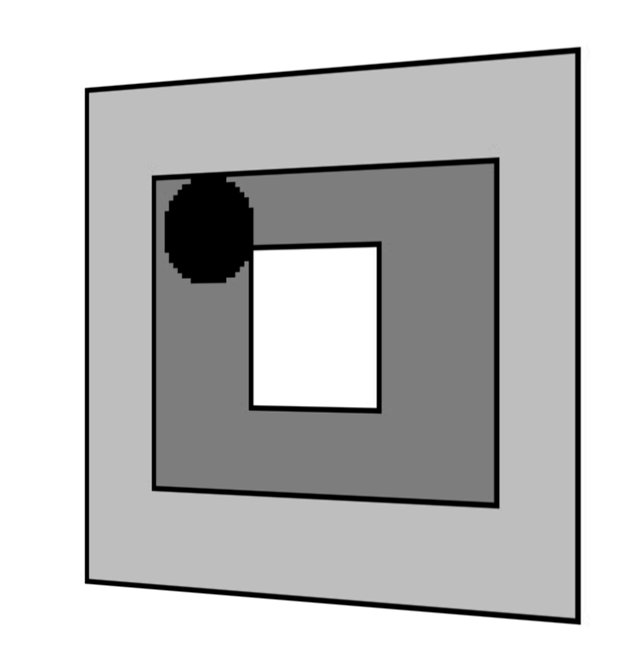

In [17]:
gif_path = viz.save_gif(aio.output_path("camera_return.gif"), frames_A, fps=5, boomerang=True)
gif_b = viz.save_gif(aio.output_path("camera_return", "camera_return_image_faithful.gif"),
                     frames_B, fps=5, boomerang=True)
print("wrote", os.path.relpath(gif_path, PROJECT_ROOT), "({:.1f} KB)".format(os.path.getsize(gif_path) / 1024))
print("wrote", os.path.relpath(gif_b, PROJECT_ROOT), "({:.1f} KB)".format(os.path.getsize(gif_b) / 1024))
print("(both loop back and forth so the sweep is visible either way round)")

from IPython.display import Image, display as _d
_d(Image(filename=gif_path))

## 1.6 Validation: rendered pixels and near-frontal misses
Re-detect corners in rendered images, then recover pose with PnP. This checks pixels
rather than reusing projected corners. Compare exact-corner PnP to isolate sensitivity
to detection noise. Both still use synthetic images and assumed calibration.
Distance remains accurate in this experiment; near-frontal tilt is sensitive
to subpixel corner errors. Measured errors and target misses are reported below.

In [18]:
rows = []
for i, (t, frame) in enumerate(zip(thetas, frames_A)):
    d = detect.detect_port(frame)                    # <- corners from the PIXELS
    pnp = camera.recover_pose_pnp(d.quad, renderA.K, geom.side_cm)
    commanded = camera.camera_pose_for_angle(float(t), C.CAMERA_DISTANCE_CM)["C"]
    rows.append({
        "step": i, "commanded_theta_deg": float(t),
        "detector_confidence": round(d.confidence, 4),
        "pnp_theta_deg": pnp["theta_deg"],
        "theta_err_deg": pnp["theta_deg"] - float(t),
        "pnp_distance_cm": pnp["distance_cm"],
        "distance_err_cm": pnp["distance_cm"] - C.CAMERA_DISTANCE_CM,
        "Cx_cm": pnp["C"][0], "Cy_cm": pnp["C"][1], "Cz_cm": pnp["C"][2],
        "centre_err_cm": float(np.linalg.norm(pnp["C"] - commanded)),
        "reproj_rmse_px": pnp["reprojection_rmse_px"],
        "n_ippe_solutions": pnp["n_solutions"],
    })
pnp_tbl = pd.DataFrame(rows)
display(pnp_tbl.round(5))

print("Evaluation targets:")
print("  theta error < {:.1f} deg,  distance error < {:.1f} cm."
      .format(C.PNP_TARGET_ANGLE_ERR_DEG, C.PNP_TARGET_DISTANCE_ERR_CM))
print()
print("MEASURED over all {} frames:".format(len(pnp_tbl)))
print("  |theta error|    : mean {:.4f} deg,  max {:.4f} deg"
      .format(pnp_tbl['theta_err_deg'].abs().mean(), pnp_tbl['theta_err_deg'].abs().max()))
print("  |distance error| : mean {:.4f} cm,   max {:.4f} cm"
      .format(pnp_tbl['distance_err_cm'].abs().mean(), pnp_tbl['distance_err_cm'].abs().max()))
print("  |centre error|   : mean {:.4f} cm,   max {:.4f} cm"
      .format(pnp_tbl['centre_err_cm'].mean(), pnp_tbl['centre_err_cm'].max()))
print("  reprojection RMSE: mean {:.4f} px,   max {:.4f} px"
      .format(pnp_tbl['reproj_rmse_px'].mean(), pnp_tbl['reproj_rmse_px'].max()))
print()
met = pnp_tbl["theta_err_deg"].abs() < C.PNP_TARGET_ANGLE_ERR_DEG
print("  distance target met on every frame : {}   (max {:.4f} cm)"
      .format(bool(pnp_tbl['distance_err_cm'].abs().max() < C.PNP_TARGET_DISTANCE_ERR_CM),
              pnp_tbl['distance_err_cm'].abs().max()))
print("  angle target met on {} of {} frames; the ones that miss are"
      .format(int(met.sum()), len(met)))
print("    theta =", sorted(pnp_tbl.loc[~met, "commanded_theta_deg"].tolist()), "deg")
print()
print("  Every miss is near the front view. The next cell separates the two possible")
print("  causes -- a wrong model, or an ill-conditioned problem -- and measures")
print("  which one it is.")

,step,commanded_theta_deg,detector_confidence,pnp_theta_deg,theta_err_deg,pnp_distance_cm,distance_err_cm,Cx_cm,Cy_cm,Cz_cm,centre_err_cm,reproj_rmse_px,n_ippe_solutions
0,0,22.5,0.8382,22.37786,-0.12214,99.88824,-0.11176,38.02876,0.01736,-92.36598,0.24122,0.12020,2
1,1,20.0,0.8429,19.81581,-0.18419,99.89432,-0.10568,33.86392,-0.00311,-93.97930,0.33826,0.21480,2
2,2,17.5,0.8566,17.64795,0.14795,99.90723,-0.09277,30.28862,-0.01712,-95.20532,0.27480,0.10973,2
3,3,15.0,0.8948,15.19361,0.19361,99.90934,-0.09066,26.18440,0.00552,-96.41708,0.34977,0.15229,2
4,4,12.5,0.8739,12.28453,-0.21547,99.90027,-0.09973,21.25544,-0.03850,-97.61285,0.39079,0.22827,2
5,5,10.0,0.8398,9.87639,-0.12361,99.89912,-0.10088,17.13500,-0.01916,-98.41863,0.23884,0.11934,2
6,6,7.5,0.8855,7.54976,0.04976,99.90566,-0.09434,13.12632,0.06769,-99.03957,0.14498,0.05085,2
7,7,5.0,0.9012,5.50532,0.50532,99.90627,-0.09373,9.58482,-0.04571,-99.44542,0.88768,0.44560,2
8,8,2.5,0.9306,4.04668,1.54668,99.91473,-0.08527,7.05084,-0.43302,-99.66469,2.73411,1.41180,2
9,9,0.0,0.8284,0.01709,0.01709,99.95510,-0.04490,0.02981,0.01839,-99.95509,0.05695,0.01071,2


Evaluation targets:
  theta error < 0.5 deg,  distance error < 1.0 cm.

MEASURED over all 10 frames:
  |theta error|    : mean 0.3106 deg,  max 1.5467 deg
  |distance error| : mean 0.0920 cm,   max 0.1118 cm
  |centre error|   : mean 0.5657 cm,   max 2.7341 cm
  reprojection RMSE: mean 0.2864 px,   max 1.4118 px

  distance target met on every frame : True   (max 0.1118 cm)
  angle target met on 8 of 10 frames; the ones that miss are
    theta = [2.5, 5.0] deg

  Every miss is near the front view. The next cell separates the two possible
  causes -- a wrong model, or an ill-conditioned problem -- and measures
  which one it is.


In [19]:
rows = []
for t in thetas:
    proj = renderA.project_port_corners(float(t))
    p = camera.recover_pose_pnp(proj, renderA.K, geom.side_cm)
    rows.append({"theta_deg": float(t), "pnp_theta_deg": p["theta_deg"],
                 "theta_err_deg": p["theta_deg"] - float(t),
                 "distance_cm": p["distance_cm"],
                 "reproj_rmse_px": p["reprojection_rmse_px"]})
exact = pd.DataFrame(rows)
display(exact.round(9))
print("max |theta error| on EXACT corners   : {:.3e} deg"
      .format(exact['theta_err_deg'].abs().max()))
print("max |distance - 100| on exact corners: {:.3e} cm"
      .format((exact['distance_cm'] - 100.0).abs().max()))
print()
print("=> the pose model, the corner ordering, the object points and every sign")
print("   are exactly right. Whatever happens at 2.5 deg is NOT a modelling error;")
print("   the only other input to PnP is the corner positions.")

,theta_deg,pnp_theta_deg,theta_err_deg,distance_cm,reproj_rmse_px
0,22.5,22.499995,-0.000005,100.000003,0.000014
1,20.0,20.000001,0.000001,100.000000,0.000014
2,17.5,17.499991,-0.000009,100.000000,0.000014
3,15.0,14.999999,-0.000001,99.999998,0.000015
4,12.5,12.499991,-0.000009,100.000001,0.000020
5,10.0,9.999997,-0.000003,100.000000,0.000008
6,7.5,7.499985,-0.000015,100.000002,0.000021
7,5.0,5.000017,0.000017,100.000001,0.000055
8,2.5,2.499997,-0.000003,100.000003,0.000055
9,0.0,0.000000,0.000000,99.999999,0.014578


max |theta error| on EXACT corners   : 1.680e-05 deg
max |distance - 100| on exact corners: 3.490e-06 cm

=> the pose model, the corner ordering, the object points and every sign
   are exactly right. Whatever happens at 2.5 deg is NOT a modelling error;
   the only other input to PnP is the corner positions.


## 1.7 Recorded benchmarks and optional checks
The tables below are **recorded results** from the full benchmark runs; the cells above
compute their own results live. The project ZIP holds the seven notebooks with the
derivations and the longer robustness experiments. The switches near the top rerun the
full angle sweep or the regression tests here.

In [20]:
display(pd.read_csv(PROJECT_ROOT/'outputs/rotation_tests/accuracy_summary.csv'))
recorded=pd.read_csv(PROJECT_ROOT/'outputs/crop_navigation_results.csv')
accepted=recorded[recorded.status=='ok']
print('Recorded crops:',len(accepted),'accepted of',len(recorded),'; max error:',accepted.loc_err_px.max(),'px')
if RUN_FULL_ROTATION_SWEEP:
    errors=[]
    for truth in range(360):
        e=rotation.estimate_rotation(rotation.rotate_image(reference,float(truth)),ref_det)
        assert e.status=='ok'
        errors.append(abs(rotation.angular_error(e.angle_deg,truth)))
    print('FRESH 360-angle MAE:',np.mean(errors),'| max:',np.max(errors))
if RUN_TESTS:
    if importlib.util.find_spec('pytest') is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q','pytest>=7.2'])
    subprocess.run([sys.executable,'-m','pytest','tests','-q','-p','no:cacheprovider'],cwd=PROJECT_ROOT,check=True)

,experiment,n,fused_MAE_deg,fused_max_deg,fused_p99_deg,marker_only_MAE_deg,marker_only_max_deg,refined_rate,status_ok_rate,min_confidence
0,"1 deg sweep, 0-359",360,0.001028,0.010438,0.010077,0.015655,0.070983,1.0,1.0,0.891175
1,200 seeded random angles,200,0.001076,0.015848,0.006217,0.015574,0.068227,1.0,1.0,0.884574


Recorded crops: 201 accepted of 300 ; max error: 0.0 px


## 1.8 Design notes, assumptions and limitations

| Topic | Design rationale |
|---|---|
| Classical vision | Known simple geometry permits explicit, inspectable methods without training data. Generalisation to real images requires separate evaluation. |
| Marker orientation | Fourfold square symmetry leaves four possible orientations; the marker resolves that ambiguity. |
| Correlation ambiguity | Flat patches and straight edges can match many positions. Texture, peak plateaus and competing peaks determine whether to accept a match. |
| Camera translation | Crop navigation assumes translation parallel to the plane at fixed scale and orientation. Pan and tilt require a projective model. |
| Homography | A 3 x 3 planar projective map with eight degrees of freedom up to scale. |
| Rendering models | The schematic proportions conflict with stated physical dimensions. The primary model preserves metric geometry; the secondary model preserves the raw frontal raster. |
| Constant-distance return | A circular orbit preserves the 100 cm radius at each commanded pose. A straight chord moves inside that radius. |
| Near-frontal pose | Weak perspective cues make tilt estimates sensitive to corner noise. Exact-corner and detected-corner PnP isolate this sensitivity. |

### Assumptions and limitations

- Confidence values are heuristics rather than calibrated probabilities.
- Ambiguous and featureless crops are rejected rather than counted as localisation successes.
- Synthetic precision does not establish real-world camera or navigation accuracy.
- Some near-frontal pose estimates miss the angle target; the measured errors are reported above.
- The return trajectory is a geometric construction. Physical motion has not been validated.

### Implementation map

| Module | Responsibility |
|---|---|
| `src/aulecv/detect.py` | Port geometry and circular marker detection |
| `src/aulecv/rotation.py` | Rotation estimation and angular error |
| `src/aulecv/navigation.py` | Crop localisation, movement planning and feedback navigation |
| `src/aulecv/closed_loop.py` | Follow-up: simulated cameras, closed-loop Parts B and D (Part 2) |
| `src/aulecv/camera.py` | Camera poses, homographies, rendering and pose recovery |
| `src/aulecv/config.py` | Thresholds and physical constants |
| `src/aulecv/viz.py` | Figures, overlays and animations |
| `tests/` | Regression tests |

### Further work

Real-camera calibration and lens-distortion correction; physical motion tests;
temporal filtering; matching under variable scale and viewpoint; and uncertainty
calibration using held-out data.

# Part 2: the follow-up

In the interview, Parts B and D were set again with one change: **the camera may not trust its own
movement.** The only thing known about a move is what was commanded. After every move the position
has to be worked out again from the image.

- **Part B**, in two versions: subtask A may zoom out for more context, subtask B may not.
- **Part D**: find the camera pose from the image (localisation and PnP) at every step, and steer
  until the estimate converges to the front view, at 100 cm, looking at the centre.

In both, the simulator keeps the true position hidden and executes every move with errors the
controller is not told about. The truth is used only afterwards, to grade the result.

## 2.1 Part B again: never trust the movement

**The follow-up task.** In the first version of Part B, the crop was located once and then every
commanded move was trusted. Here the camera's real position is hidden, every move is executed
with errors the navigator is not told about, and **after every move the camera works out where it
is from the image alone.** The only thing the navigator knows about a move is what it asked for.

Two versions, as asked:

- **A. With zoom:** when a view can't be located, zoom out until it can, travel zoomed out, and zoom
  back in once the marker is in view.
- **B. Without zoom:** map in advance which views *can* be located, and plan a route that stays on
  them. Use single-axis fixes to correct drift while probing across a ridge; never integrate commanded motion.

Code: `src/aulecv/closed_loop.py`. Tests: `tests/test_closed_loop.py`.

### 2.1.1 The problem: some views cannot be located

Template matching only works if the view contains something unique. A view showing only straight
horizontal lines looks the same all along those lines. Re-localising at every step of the
**original** Part B plan shows how often that happens.

In [21]:
reference = aio.load_reference()
ref_det = detect.detect_port(reference)
VIEW = (200, 170)
ppc = navigation.pixels_per_cm(ref_det)

loc0 = navigation.localize_crop(navigation.extract_crop(reference, 400, 380, *VIEW), reference)
plan0 = navigation.plan_crop_movements(loc0, ref_det, reference.shape)
statuses = [navigation.localize_crop(navigation.extract_crop(reference, *c.window_after), reference).status
            for c in plan0.commands]
runs, prev = [], None
for k, s in enumerate(statuses, 1):
    if s != prev: runs.append([k, k, s]); prev = s
    else: runs[-1][1] = k
for a, b, s in runs:
    print(f"steps {a:>2} to {b:<2}: {s}")
print(f"\n{statuses.count('ambiguous')} of {len(statuses)} views along the original route cannot be located on their own.")

steps  1 to 8 : ok
steps  9 to 36: ambiguous
steps 37 to 65: ok

28 of 65 views along the original route cannot be located on their own.


In the middle stretch the view only contains the bottom horizontal lines, so it knows its height but
not how far left or right it is (the aperture problem). The original plan got through it only by
trusting its own moves. With real motion errors, that doesn't work, as 2.1.3 shows.

### 2.1.2 The simulated camera

`cl.PanCamera` keeps the true position to itself. The navigator can only:

- `capture()` to get the current view,
- `move_cm(dx, dy)` to ask for a move, which is executed with a **scale error per axis, a bias, and
  random noise**,
- `set_zoom(s)`, where zoom `s` shows `s` times more of the scene in the same number of pixels.

For the example below the camera really moves only **75%** of what it's told left and right,
**120%** up and down, plus a small bias and noise. The navigator doesn't know any of that.

In [22]:
START = (500.0, 465.0)                     # centre of the original Part B crop
ERR = cl.MotionError(gain=(0.75, 1.2), bias_px=(0.5, -0.5), noise_px=1.0, seed=7)
PAD = 300                                  # plain background around the port, so zoomed-out views fit
loc_native = cl.Localizer(reference, VIEW)
loc_padded = cl.Localizer(reference, VIEW, pad=PAD)

def truly_visible(c):
    return c.true_marker_visible(ref_det)  # evaluator only

def show_paths(ax, cams_and_labels, title):
    viz.show(reference, title, ax=ax)
    mk = ref_det.marker_center
    ax.add_patch(plt.Circle(mk, ref_det.marker_radius_px, fill=False, color="red", lw=1.5))
    for c, label, style in cams_and_labels:
        t = np.array(c.trail)
        ax.plot(t[:, 0], t[:, 1], style, lw=1.6, ms=3, label=label)
    ax.legend(loc="lower right", fontsize=8)

### 2.1.3 The old way: trust the movement

Localise once, compute the route, and send every move without looking again.

believes it arrived      : True
marker really in view    : False
where it thinks it is vs where it is: 114.1 px apart


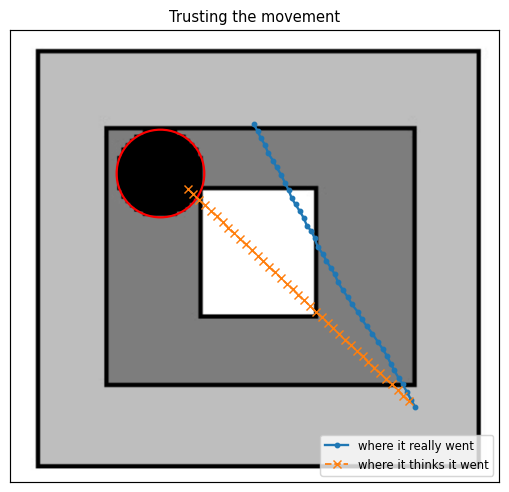

In [23]:
cam_trust = cl.PanCamera(reference, START, VIEW, ppc, ERR)
r_trust = cl.navigate_trusting_motion(cam_trust, loc_native, ref_det, reference.shape)
print("believes it arrived      :", r_trust.status == "visible")
print("marker really in view    :", truly_visible(cam_trust))
print("where it thinks it is vs where it is: {:.1f} px apart".format(r_trust.final_error_px(cam_trust)))
believed = np.array([[e["believed_x"], e["believed_y"]] for e in r_trust.log])
fig, ax = plt.subplots(figsize=(6, 5.6))
show_paths(ax, [(cam_trust, "where it really went", "o-")], "Trusting the movement")
ax.plot(believed[:, 0], believed[:, 1], "x--", lw=1.2, label="where it thinks it went"); ax.legend(loc="lower right", fontsize=8)
fig.savefig(aio.output_path("crop_navigation", "followup_trust_motion.png"), bbox_inches="tight"); plt.show()

It reports success, but the marker isn't in view. That's the dangerous failure: being wrong
**without knowing it**.

### 2.1.4 Subtask A: with zoom

After every move the view is located again by template matching at the current zoom. A view at
zoom `s` shows the scene shrunk by `s`, so it's matched against a copy of the scene shrunk by the
same amount.

1. **Located:** move towards the marker.
2. **Not located:** zoom out one step (1, 1.5, 2, 3) and look again. Zoomed out, the view contains
   more structure, so it can usually be placed.
3. **Keep travelling** at the zoom that worked.
4. **Once the estimated native view holds the marker:** zoom back in to 1 and confirm from a
   native-zoom fix.

The zoom setting itself is assumed to be read back from the lens.

In [24]:
cam_zoom = cl.PanCamera(reference, START, VIEW, ppc, ERR, pad=PAD, max_zoom=3.0)
r_zoom = cl.navigate_with_zoom(cam_zoom, loc_padded, ref_det, reference.shape, axis_first=True)
print("status:", r_zoom.status, "| marker really in view:", truly_visible(cam_zoom))
print("moves:", r_zoom.moves, "| zoom changes:", r_zoom.zoom_changes, "| views it could not place:", r_zoom.lost_views)
print("final estimate vs truth: {:.2f} px".format(r_zoom.final_error_px(cam_zoom)))
# Join evaluator truth AFTER control, paired with the same captured frame.
events = pd.concat([pd.DataFrame(r_zoom.log), pd.DataFrame(cam_zoom.observations)], axis=1)
display(events[events.event != "move"][["moves", "zoom", "status", "event", "est_x", "est_y", "true_x", "true_y"]])

status: visible | marker really in view: True
moves: 59 | zoom changes: 2 | views it could not place: 1
final estimate vs truth: 0.20 px


,moves,zoom,status,event,est_x,est_y,true_x,true_y
5,5,1.0,ambiguous,zoom out,NaN,NaN,471.340359,449.636247
60,59,1.5,ok,zoom in to confirm,224.782067,192.0,224.805320,192.983190
61,59,1.0,ok,arrived,225.000000,193.0,224.805320,192.983190


**Diagonal moves.** By default each command is the straight-line vector from the
estimated position to the goal, so x and y change together: the camera moves
diagonally. `axis_first=True` instead moves along the larger offset first, like the
original Part B route; the run above uses it so the two routes can be compared step
by step. Either way the position is measured again after every move, so a diagonal
step that lands wrong is corrected on the next one. (Without zoom, the planned
route allows diagonal steps too: it searches over all eight neighbours.)

Same starts and same hidden motion errors, both ways:

In [25]:
rng = np.random.default_rng(77)
H, W = reference.shape[:2]
rows = []
for k in range(12):
    start = (rng.uniform(VIEW[0] / 2, W - VIEW[0] / 2), rng.uniform(VIEW[1] / 2, H - VIEW[1] / 2))
    err = cl.MotionError(gain=tuple(rng.uniform(0.5, 1.5, 2)), bias_px=tuple(rng.uniform(-2, 2, 2)),
                         noise_px=1.5, seed=int(rng.integers(1e9)))
    for axis_first in (False, True):
        c = cl.PanCamera(reference, start, VIEW, ppc, err, pad=PAD, max_zoom=3.0)
        r = cl.navigate_with_zoom(c, loc_padded, ref_det, reference.shape, axis_first=axis_first)
        rows.append({"moves": "one axis at a time" if axis_first else "diagonal (default)",
                     "reached": truly_visible(c), "moves_used": r.moves})
display(pd.DataFrame(rows).groupby("moves").agg(runs=("reached", "size"), reached=("reached", "sum"),
        median_moves=("moves_used", "median"), max_moves=("moves_used", "max")))

,runs,reached,median_moves,max_moves
moves,,,,
diagonal (default),12,12,15.0,39
one axis at a time,12,12,16.5,40


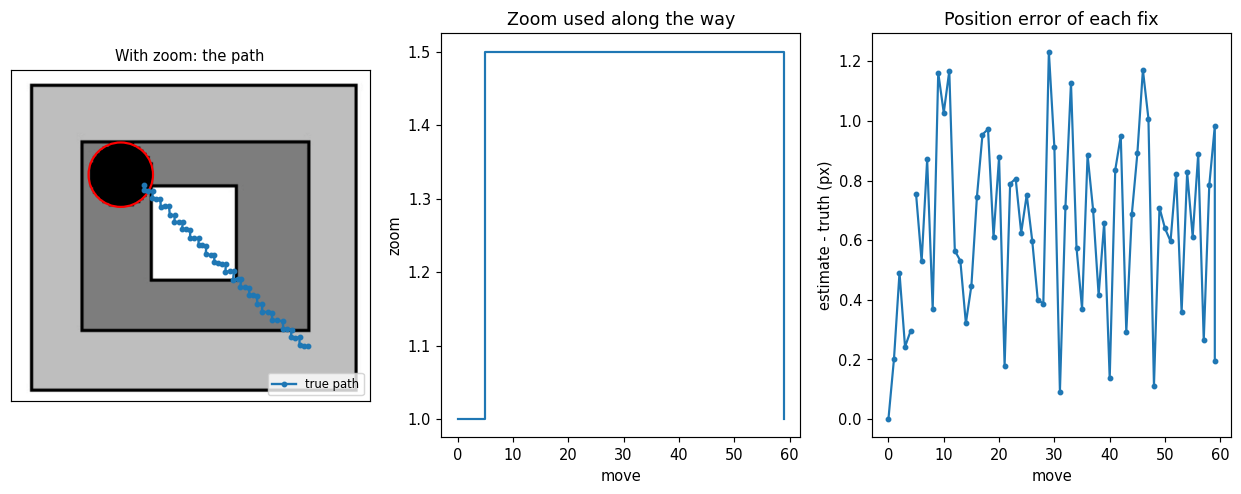

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
show_paths(axes[0], [(cam_zoom, "true path", "o-")], "With zoom: the path")
z = events.zoom.to_numpy(); m = events.moves.to_numpy()
axes[1].step(m, z, where="post"); axes[1].set_xlabel("move"); axes[1].set_ylabel("zoom"); axes[1].set_title("Zoom used along the way")
err = np.hypot(events.est_x.astype(float) - events.true_x, events.est_y.astype(float) - events.true_y)
err = err.where(events.status == "ok")  # rejected matches are not position fixes
axes[2].plot(m, err, "o-", ms=3); axes[2].set_xlabel("move"); axes[2].set_ylabel("estimate - truth (px)")
axes[2].set_title("Position error of each fix")
fig.savefig(aio.output_path("crop_navigation", "followup_with_zoom.png"), bbox_inches="tight"); plt.show()

### 2.1.5 Subtask B: without zoom

Without zoom, the camera can't step back to see more, so it plans where to look:

1. **Localisability map, computed once:** crop the view at every grid position (every 10 px) and
   ask the same localiser whether it can be placed.
2. **Route:** the cheapest path to the marker over the grid. Steps on views that can be placed are
   cheap, and cheaper the further they are from views that can't (a safety margin). Steps on views
   that can't be placed are very expensive, so the route only uses them to cross a gap between
   separate areas, where the gap is narrowest.
3. **After every move:** locate again and re-plan from that fix.
4. **If a view the map promised turns out unplaceable** (the move landed somewhere unexpected),
   request a reverse move once and avoid that planned cell. Re-localise; a reverse command
   is not proof of returning to the old position. Across a planned gap, repeat bounded probes
   toward the next informative region, checking every new image. No dead-reckoned position
   is used, and only a fresh confident fix can establish arrival.

In [27]:
import time
t0 = time.time()
lmap = cl.LocalizabilityMap(reference, loc_native, ref_det)
print("map: {} positions, {:.0%} can be located, {:.0%} have a full margin around them ({:.0f} s)"
      .format(lmap.ok.size, lmap.fraction_ok, lmap.safe.mean(), time.time() - t0))
cam_map = cl.PanCamera(reference, START, VIEW, ppc, ERR)
r_map = cl.navigate_without_zoom(cam_map, loc_native, lmap, ref_det)
print("status:", r_map.status, "| marker really in view:", truly_visible(cam_map))
print("moves:", r_map.moves, "| blind views:", r_map.lost_views, "| partial views:", r_map.partial_views, "| reverse attempts:", r_map.backoffs)
print("final estimate vs truth: {:.2f} px".format(r_map.final_error_px(cam_map)))

map: 1599 positions, 89% can be located, 78% have a full margin around them (18 s)


status: visible | marker really in view: True
moves: 52 | blind views: 0 | partial views: 0 | reverse attempts: 0
final estimate vs truth: 0.41 px


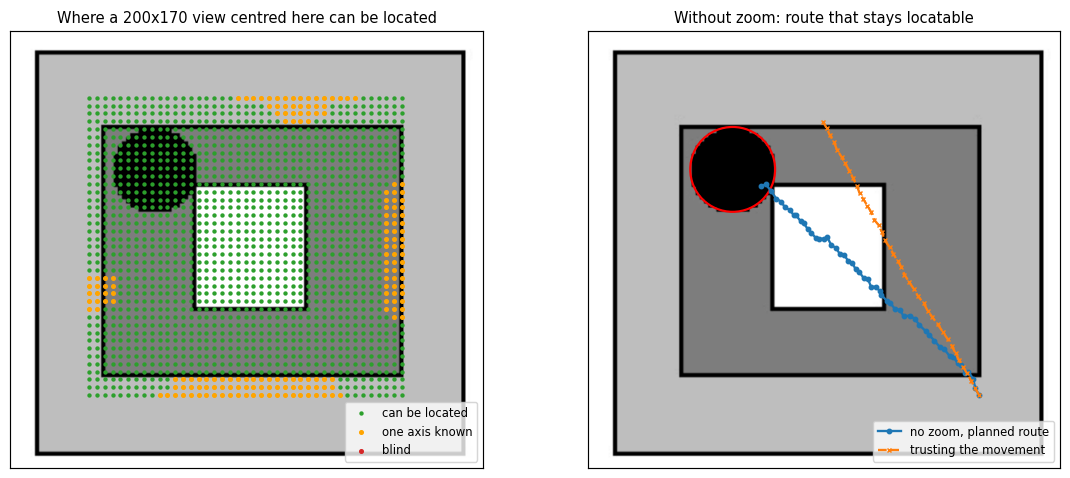

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
okc = np.array([lmap.center_of((j, i)) for j in range(lmap.ok.shape[0]) for i in range(lmap.ok.shape[1]) if lmap.ok[j, i]])
bad = np.array([lmap.center_of((j, i)) for j in range(lmap.ok.shape[0]) for i in range(lmap.ok.shape[1]) if not lmap.ok[j, i] and not lmap.partial[j, i]]).reshape(-1, 2)
partial = np.array([lmap.center_of((j, i)) for j in range(lmap.ok.shape[0]) for i in range(lmap.ok.shape[1]) if lmap.partial[j, i]]).reshape(-1, 2)
viz.show(reference, "Where a 200x170 view centred here can be located", ax=axes[0])
axes[0].scatter(okc[:, 0], okc[:, 1], s=4, c="tab:green", label="can be located")
axes[0].scatter(partial[:, 0], partial[:, 1], s=6, c="orange", label="one axis known")
axes[0].scatter(bad[:, 0], bad[:, 1], s=6, c="tab:red", label="blind")
axes[0].legend(loc="lower right", fontsize=8)
show_paths(axes[1], [(cam_map, "no zoom, planned route", "o-"), (cam_trust, "trusting the movement", "x--")],
           "Without zoom: route that stays locatable")
fig.savefig(aio.output_path("crop_navigation", "followup_without_zoom.png"), bbox_inches="tight"); plt.show()

### 2.1.6 Many runs, random starts, random motion errors

For each run: a random starting view (some can't be located at all), and a random motion error
per axis (50% to 150% of the commanded distance), plus bias and noise. Every method gets exactly the
same runs. "Re-localise only" re-localises after every move but has neither trick: when lost, it
searches blindly.

The same is repeated with a smaller **120 x 100** view, where far fewer views can be located.

In [29]:
if FULL_RUNS:
    def compare(view, n_runs, seed):
        lc0 = cl.Localizer(reference, view, partial_axes=False)  # unchanged all-or-nothing baselines
        lcp, lcz = cl.Localizer(reference, view), cl.Localizer(reference, view, pad=PAD)
        mp = lmap if view == VIEW else cl.LocalizabilityMap(reference, lcp, ref_det)
        H, W = reference.shape[:2]
        rng = np.random.default_rng(seed); rows = []
        for k in range(n_runs):
            start = (rng.uniform(view[0] / 2, W - view[0] / 2), rng.uniform(view[1] / 2, H - view[1] / 2))
            err = cl.MotionError(gain=tuple(rng.uniform(0.5, 1.5, 2)), bias_px=tuple(rng.uniform(-2, 2, 2)),
                                 noise_px=1.5, seed=int(rng.integers(1e9)))
            for name in ["trust the movement", "re-localise only", "A: with zoom", "B: no zoom, planned route"]:
                if name == "A: with zoom":
                    c = cl.PanCamera(reference, start, view, ppc, err, pad=PAD, max_zoom=3.0)
                    r = cl.navigate_with_zoom(c, lcz, ref_det, reference.shape, axis_first=True)
                else:
                    c = cl.PanCamera(reference, start, view, ppc, err)
                    if name == "trust the movement":
                        r = cl.navigate_trusting_motion(c, lc0, ref_det, reference.shape)
                    elif name == "re-localise only":
                        r = cl.navigate_with_zoom(c, lc0, ref_det, reference.shape, zoom_levels=(1.0,), axis_first=True)
                    else:
                        r = cl.navigate_without_zoom(c, lcp, mp, ref_det)
                vis = c.true_marker_visible(ref_det)
                rows.append({"view": f"{view[0]}x{view[1]}", "method": name, "reached": vis,
                             "claimed_but_wrong": r.status == "visible" and not vis, "moves": r.moves,
                             "lost_views": r.lost_views, "partial_views": r.partial_views, "zoom_changes": r.zoom_changes, "undos": r.backoffs,
                             "final_error_px": r.final_error_px(c)})
        return pd.DataFrame(rows), mp
    
    t0 = time.time()
    df_big, _ = compare(VIEW, 40, C.RANDOM_SEED)
    df_small, lmap_small = compare((120, 100), 30, C.RANDOM_SEED + 1)
    print("{:.0f} s; small-view map: {:.0%} of positions can be located".format(time.time() - t0, lmap_small.fraction_ok))
    allruns = pd.concat([df_big, df_small])
    allruns.to_csv(aio.output_path("crop_navigation", "followup_closed_loop_runs.csv"), index=False)
    summary = (allruns.groupby(["view", "method"], sort=False)
               .agg(runs=("reached", "size"), reached=("reached", "mean"), wrong_claims=("claimed_but_wrong", "sum"),
                    median_moves=("moves", "median"), lost_views=("lost_views", "sum"), partial_views=("partial_views", "sum"),
                    zoom_changes=("zoom_changes", "sum"), undos=("undos", "sum"),
                    worst_final_error_px=("final_error_px", "max")))
    summary["reached"] = (100 * summary["reached"]).round(0).astype(int).astype(str) + "%"
    display(summary.round(2))
    summary.to_csv(aio.output_path("crop_navigation", "followup_closed_loop_summary.csv"))
else:
    print("Previously computed randomised Part B study; set FULL_RUNS=True to recompute")
    summary = pd.read_csv(aio.output_path("crop_navigation", "followup_closed_loop_summary.csv"))
    display(summary)


Previously computed randomised Part B study; set FULL_RUNS=True to recompute


,view,method,runs,reached,wrong_claims,median_moves,lost_views,partial_views,zoom_changes,undos,worst_final_error_px
0,200x170,trust the movement,40,22%,31,17.0,12,0,0,0,149.255543
1,200x170,re-localise only,40,100%,0,17.5,12,0,0,0,0.574132
2,200x170,A: with zoom,40,100%,0,17.5,2,4,12,0,0.574132
3,200x170,"B: no zoom, planned route",40,100%,0,17.0,0,45,0,0,0.661701
4,120x100,trust the movement,30,40%,18,20.0,102,0,0,0,139.543746
5,120x100,re-localise only,30,100%,0,32.5,355,0,0,0,0.535002
6,120x100,A: with zoom,30,100%,0,22.0,26,19,67,0,0.664710
7,120x100,"B: no zoom, planned route",30,100%,0,30.0,121,320,0,7,0.614384


**How to read this**

- **Trusting the movement** fails most of the time, and in most of those failures it *claims* it
  arrived. That's the case to rule out.
- Arrival is accepted only from a full image-based fix. Partial fixes never count as arrival.
- With the big view, most views can be located, so re-localising alone is nearly enough.
- With the **small view**, plain re-localising only gets there by searching blindly, with hundreds
  of views it can't place. Compare blind and partial views separately: one known coordinate
  is useful even though the full position is not known. The map prices full, partial and blind
  cells differently. It prefers full fixes, then partial fixes, then blind search.

### 2.1.7 Keeping the coordinate that the image actually tells us

A horizontal score ridge now returns `y_only`, a measured y and an x interval. A vertical ridge
returns `x_only`. The full centre is `None`: the interval midpoint is never treated as a position.
The matcher checks **all** plausible competing peaks, requires a strong score, and rejects an axis
if competing lines give different coordinates. The map gives partial cells an intermediate cost.

At the first partial frame, save the observed coordinate as an anchor. Each new image corrects
drift relative to that anchor, while bounded steps probe along the unknown axis toward a ridge end.
Neither the anchor nor the candidate interval is updated from commanded movement. Once a full
fix returns, normal planning resumes. Zoom still takes priority when available.

This live example starts in the old blind middle and has a 2-pixel vertical bias per move.

status: y_only full centre: None y: 465.0
image-only x/y bounds: [[189.5 428.5]
 [463.5 466.5]]


result: visible actual visibility: True partial frames: 17


,capture,est_x,est_y,x_range,command_cm
0,0,NaN,465.0,"(189.5, 428.5)","(-0.7272727272727273, 0.0)"
1,1,NaN,467.0,"(187.5, 430.5)","(-0.7131495823206693, -0.15144103099473658)"
2,2,NaN,467.0,"(187.5, 430.5)","(-0.7131495823206693, -0.15144103099473658)"
3,3,NaN,466.0,"(188.5, 429.5)","(-0.7236634110618103, -0.07683684866486395)"
4,4,NaN,467.0,"(187.5, 430.5)","(-0.7131495823206693, -0.15144103099473658)"
5,5,NaN,467.0,"(187.5, 430.5)","(-0.7131495823206693, -0.15144103099473658)"
6,6,NaN,467.0,"(187.5, 430.5)","(-0.7131495823206693, -0.15144103099473658)"
7,7,NaN,467.0,"(187.5, 430.5)","(-0.7131495823206693, -0.15144103099473658)"


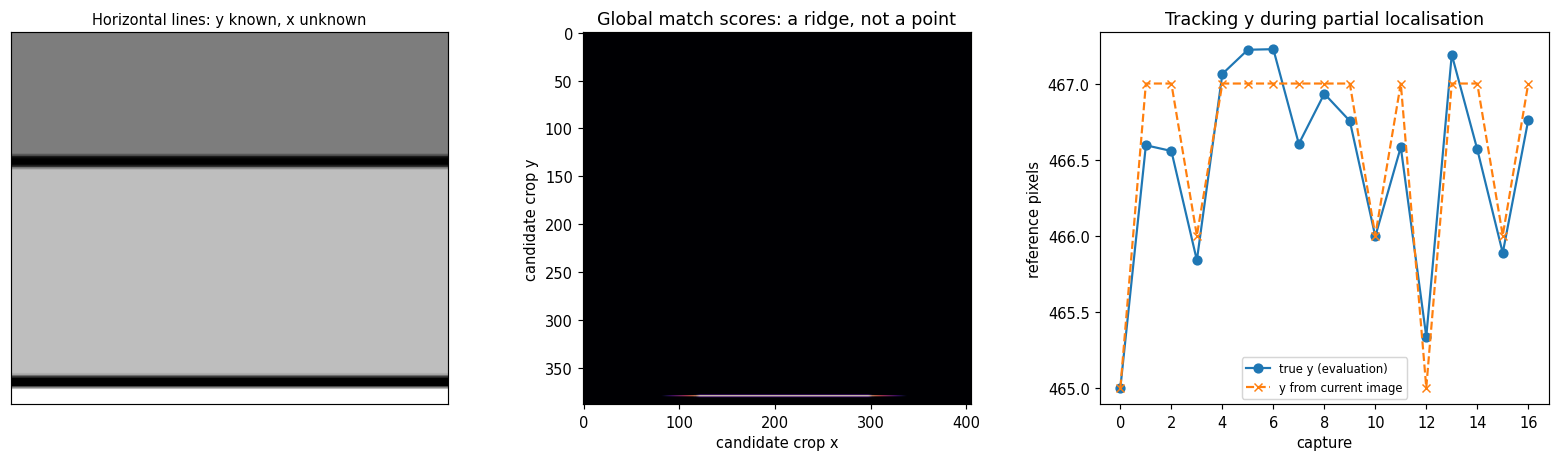

In [30]:
view = navigation.extract_crop(reference, 188, 380, *VIEW)
fix = loc_native.locate(view)
print("status:", fix.status, "full centre:", fix.center, "y:", fix.coordinate(1))
print("image-only x/y bounds:", fix.axis_bounds)
scores = cv2.matchTemplate(aio.to_gray(reference).astype(np.float32), aio.to_gray(view).astype(np.float32), cv2.TM_CCOEFF_NORMED)
c_partial = cl.PanCamera(reference, (288, 465), VIEW, ppc, cl.MotionError(gain=(0.7, 1.2), bias_px=(0.5, 2), noise_px=0.5, seed=93))
r_partial = cl.navigate_without_zoom(c_partial, loc_native, lmap, ref_det)
pe = pd.concat([pd.DataFrame(r_partial.log), pd.DataFrame(c_partial.observations)], axis=1)
print("result:", r_partial.status, "actual visibility:", c_partial.true_marker_visible(ref_det), "partial frames:", r_partial.partial_views)
display(pe.loc[pe.status == "y_only", ["capture", "est_x", "est_y", "x_range", "command_cm"]].head(8))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
viz.show(view, "Horizontal lines: y known, x unknown", ax=axes[0])
axes[1].imshow(scores, cmap="magma", vmin=0.9, vmax=1.0, origin="upper")
axes[1].set_title("Global match scores: a ridge, not a point")
axes[1].set_xlabel("candidate crop x"); axes[1].set_ylabel("candidate crop y")
mask = pe.status == "y_only"
axes[2].plot(pe.capture, pe.true_y.where(mask), "o-", label="true y (evaluation)")
axes[2].plot(pe.capture, pe.est_y.where(mask), "x--", label="y from current image")
axes[2].set_title("Tracking y during partial localisation")
axes[2].set_xlabel("capture"); axes[2].set_ylabel("reference pixels"); axes[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(aio.output_path("crop_navigation", "followup_partial_axis.png"), bbox_inches="tight"); plt.show()
pe.to_csv(aio.output_path("crop_navigation", "followup_partial_axis_trace.csv"), index=False)

### 2.1.8 Limitations

- The camera is simulated: the scene is the flat reference image, and moves are translations parallel
  to it. Rotation, scale change from moving closer, lens distortion and lighting are not modelled.
- The zoom level is assumed to be read back exactly from the lens. A scale search in the matcher
  would remove that assumption.
- The localisability map is computed from the reference, so it assumes the scene matches it.
- Partial-axis bounds are score-threshold envelopes, not calibrated probability intervals.
  All competing peaks are checked: two identical lines at different heights do not give a y fix.
- A blank or repeated view cannot uniquely determine position. During a gap crossing, commands
  are search actions only: no position is updated from them. Probes and fallback spiral search
  have a shared movement budget and may exhaust it. Successful example runs are not a guarantee
  for every scene, start, or actuator failure.

## 2.2 Part D again: find the camera from the image at every step

**The follow-up task.** The first Part D rendered poses it already knew. Here the camera's real
pose is hidden, every commanded move is executed with errors, and **after every move the camera
works out where it is from the image**, then decides its next move from that estimate. The
estimated angle should converge to 0, at 100 cm, looking at the centre.

Code: `src/aulecv/closed_loop.py`. Tests: `tests/test_closed_loop.py`.

### 2.2.1 Finding the pose from one image

Two steps:

1. **Four corners plus PnP.** Detect the outer square's corners and solve PnP against the real
   40 cm square. This is quick and robust. But near the front view, a slightly turned square looks
   almost unchanged, so the angle is weak (the original Part D showed this).
2. **Refine with every pixel.** Use the PnP answer as a starting guess, then align the whole
   reference image to the camera image (ECC, a dense image alignment). That gives the homography
   between them, using every pixel instead of four corners. Decomposition of `K^-1 H G^-1`
   seeds a final PnP fit to a 5 x 5 grid of ECC-aligned target points. These correlated points
   constrain a physical 6-DOF camera; they are not 25 independent feature detections.

If the alignment fails or scores badly, the corner answer is used and flagged.

In [31]:
reference = aio.load_reference()
ref_det = detect.detect_port(reference)
geom = camera.PortGeometry.from_detection(ref_det, reference.shape)
thetas = camera.generate_return_sequence(C.PART_C_ANGLE_DEG, C.PART_D_STEP_DEG)
renderA = camera.make_renderer(geom, thetas, "metric")
estimator = cl.PoseEstimator(reference, renderA.K, renderA.G)

rows = []
for true_theta in [22.5, 15.0, 10.0, 5.0, 2.5, 1.0, 0.5, 0.0]:
    probe = cl.OrbitCamera(reference, renderA, true_theta, 100.0, cl.PoseError(sensor_noise=2.0, seed=3))
    e = estimator.estimate(probe.capture())
    rows.append({"true_theta_deg": true_theta,
                 "corner_PnP_error_deg": e.corner_theta_deg - true_theta,
                 "dense_error_deg": e.theta_deg - true_theta,
                 "corner_distance_error_cm": e.corner_distance_cm - 100.0,
                 "dense_distance_error_cm": e.distance_cm - 100.0, "method": e.method})
acc = pd.DataFrame(rows)
display(acc.round(4))
print("worst corner-PnP angle error : {:.3f} deg".format(acc.corner_PnP_error_deg.abs().max()))
print("worst dense angle error      : {:.3f} deg".format(acc.dense_error_deg.abs().max()))
acc.to_csv(aio.output_path("camera_return", "followup_pose_accuracy.csv"), index=False)

,true_theta_deg,corner_PnP_error_deg,dense_error_deg,corner_distance_error_cm,dense_distance_error_cm,method
0,22.5,-0.1280,-0.0009,-0.1083,-0.0020,dense
1,15.0,0.1879,0.0046,-0.0882,0.0022,dense
2,10.0,-0.1202,0.0012,-0.1018,-0.0033,dense
3,5.0,0.5021,-0.0058,-0.0933,0.0022,dense
4,2.5,1.4306,-0.0091,-0.0883,-0.0035,dense
5,1.0,0.9212,0.0056,-0.0962,0.0035,dense
6,0.5,2.6467,-0.0108,-0.1830,-0.0003,dense
7,0.0,0.0171,0.0045,-0.0449,0.0019,dense


worst corner-PnP angle error : 2.647 deg
worst dense angle error      : 0.011 deg


The corner answer is off by over a degree near the front. The dense answer stays within a few
hundredths of a degree everywhere, with image noise added.

### 2.2.2 The simulated camera

`cl.OrbitCamera` keeps the true pose to itself and renders the image from it. The controller sends
a move in the camera's own frame: a translation plus a rotation. It's executed with errors:

- only **85%** of the commanded translation,
- random translation noise (0.05 cm per axis),
- random rotation noise (0.05 degrees per axis),
- image noise.

### 2.2.3 The closed loop

Each iteration:

1. Estimate the pose from the image.
2. Require full 3-D position within 0.1 cm of `(0, 0, -100)`, orientation, pointing and
   azimuth errors below 0.1 degrees, on two consecutive frames. Hold still for confirmation.
3. Otherwise aim for the orbit point up to 2.5 degrees closer to the front, at 100 cm, looking at
   the centre, and send the move needed to get there **from the estimated pose**. Distance and
   pointing errors get corrected on the way.

In [32]:
ERR = cl.PoseError(gain=0.85, noise_cm=0.05, rot_noise_deg=0.05, sensor_noise=2.0, seed=11)

class Recording(cl.OrbitCamera):
    def capture(self):
        img = super().capture(); self.frames.append(img); return img

def run(refine):
    c = Recording(reference, renderA, 22.5, 100.0, ERR); c.frames = []
    res = cl.return_to_front_closed_loop(c, estimator, refine=refine)
    # Truth stays in the evaluator, outside the controller's interface.
    return c, res, pd.concat([pd.DataFrame(res.log), pd.DataFrame(c.observations)], axis=1)

cam_dense, res_dense, log_dense = run(True)
cam_corner, res_corner, log_corner = run(False)
print("dense  : {} after {} iterations | true angle {:.3f} deg, true distance {:.3f} cm"
      .format(res_dense.status, res_dense.iterations, cam_dense.true_theta_deg, cam_dense.true_distance_cm))
print("corners: {} after {} iterations | true angle {:.3f} deg, true distance {:.3f} cm"
      .format(res_corner.status, res_corner.iterations, cam_corner.true_theta_deg, cam_corner.true_distance_cm))
display(log_dense[["iteration", "true_theta_deg", "est_theta_deg", "corner_theta_deg",
                   "true_distance_cm", "est_distance_cm", "true_pointing_err_deg", "method"]].round(4))
log_dense.to_csv(aio.output_path("camera_return", "followup_closed_loop_dense.csv"), index=False)
log_corner.to_csv(aio.output_path("camera_return", "followup_closed_loop_corners.csv"), index=False)

dense  : converged after 16 iterations | true angle -0.017 deg, true distance 99.942 cm
corners: not_converged after 30 iterations | true angle -0.664 deg, true distance 100.192 cm


,iteration,true_theta_deg,est_theta_deg,corner_theta_deg,true_distance_cm,est_distance_cm,true_pointing_err_deg,method
0,0,22.5000,22.4998,22.3751,100.0000,99.9994,0.0000,dense
1,1,20.3792,20.3824,20.4882,99.9642,99.9648,0.3086,dense
2,2,18.2753,18.2753,18.3128,100.0355,100.0359,0.4458,dense
3,3,16.1475,16.1441,16.0998,99.9767,99.9746,0.3381,dense
4,4,14.0688,14.0663,14.0086,99.9371,99.9358,0.4643,dense
5,5,11.9666,11.9670,11.6354,100.0303,100.0289,0.3411,dense
6,6,9.8037,9.8032,9.7576,100.0270,100.0286,0.3180,dense
7,7,7.6812,7.6864,7.8172,99.9447,99.9419,0.2744,dense
8,8,5.5288,5.5368,5.2638,100.0424,100.0392,0.4144,dense
9,9,3.3889,3.3900,3.2907,99.9338,99.9308,0.3586,dense


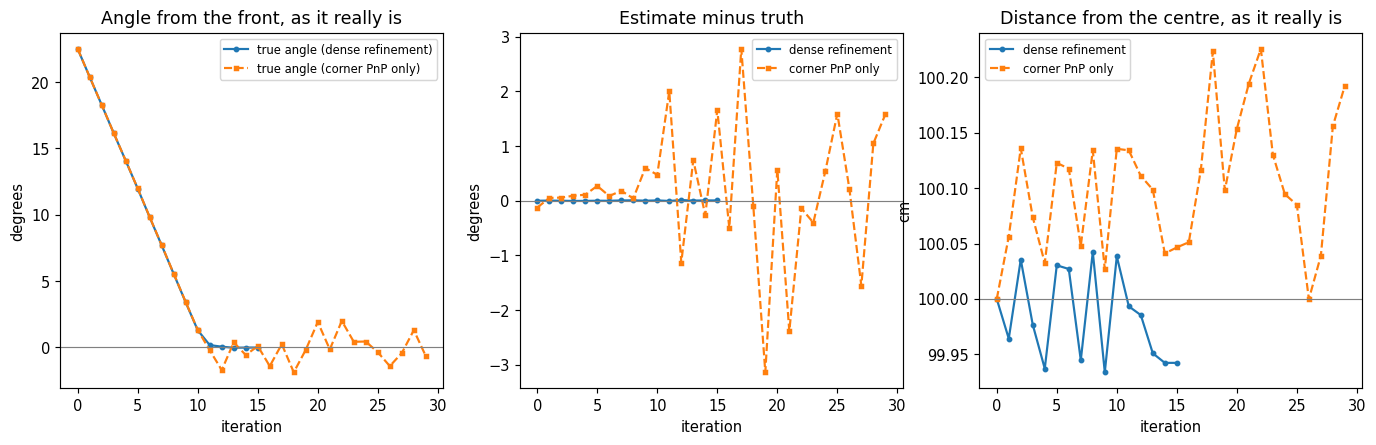

wrote outputs\camera_return\followup_closed_loop_return.gif


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for lg, name, style in [(log_dense, "dense refinement", "o-"), (log_corner, "corner PnP only", "s--")]:
    axes[0].plot(lg.iteration, lg.true_theta_deg, style, ms=3, label=f"true angle ({name})")
    axes[1].plot(lg.iteration, lg.est_theta_deg - lg.true_theta_deg, style, ms=3, label=name)
    axes[2].plot(lg.iteration, lg.true_distance_cm, style, ms=3, label=name)
axes[0].axhline(0, color="grey", lw=0.8); axes[0].set_title("Angle from the front, as it really is")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("degrees"); axes[0].legend(fontsize=8)
axes[1].axhline(0, color="grey", lw=0.8); axes[1].set_title("Estimate minus truth")
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("degrees"); axes[1].legend(fontsize=8)
axes[2].axhline(100, color="grey", lw=0.8); axes[2].set_title("Distance from the centre, as it really is")
axes[2].set_xlabel("iteration"); axes[2].set_ylabel("cm"); axes[2].legend(fontsize=8)
fig.savefig(aio.output_path("camera_return", "followup_convergence.png"), bbox_inches="tight"); plt.show()
gif = viz.save_gif(aio.output_path("camera_return", "followup_closed_loop_return.gif"), cam_dense.frames, fps=4)
print("wrote", os.path.relpath(gif, PROJECT_ROOT))

**With dense refinement** the estimate tracks the truth to about a hundredth of a degree, and the
camera settles at the front.

**With corners only** it never settles. Near the front its estimate is off by a degree or more, so
it keeps "correcting" errors that aren't there and hunts back and forth around 0. That's the
near-front weakness from the original Part D, and now it has a fix.

### 2.2.4 Many runs with random errors

In [34]:
if FULL_RUNS:
    rng = np.random.default_rng(C.RANDOM_SEED); rows = []
    for k in range(8):
        err = cl.PoseError(gain=float(rng.uniform(0.7, 1.2)), noise_cm=0.05, rot_noise_deg=0.05,
                           sensor_noise=2.0, seed=int(rng.integers(1e9)))
        for refine in (True, False):
            c = cl.OrbitCamera(reference, renderA, 22.5, 100.0, err)
            res = cl.return_to_front_closed_loop(c, estimator, refine=refine)
            last = res.log[-1]
            rows.append({"run": k, "method": "dense refinement" if refine else "corner PnP only",
                         "motion_gain": round(err.gain, 3), "status": res.status, "iterations": res.iterations,
                         "final_true_angle_deg": c.true_theta_deg, "final_true_distance_cm": c.true_distance_cm,
                         "final_estimate_error_deg": last["est_theta_deg"] - c.observations[-1]["true_theta_deg"],
                         "final_position_error_cm": np.linalg.norm(c.true_center - [0, 0, -100]),
                         "final_pointing_error_deg": c.true_pointing_error_deg,
                         "max_radius_deviation_cm": max(abs(o["true_distance_cm"] - 100) for o in c.observations)})
    runs = pd.DataFrame(rows)
    runs.to_csv(aio.output_path("camera_return", "followup_closed_loop_runs.csv"), index=False)
    summary = runs.groupby("method").agg(
        converged=("status", lambda s: f"{(s == 'converged').sum()} of {len(s)}"),
        median_iterations=("iterations", "median"),
        worst_final_angle_deg=("final_true_angle_deg", lambda s: s.abs().max()),
        worst_final_distance_error_cm=("final_true_distance_cm", lambda s: (s - 100).abs().max()),
        worst_estimate_error_deg=("final_estimate_error_deg", lambda s: s.abs().max()),
        worst_position_error_cm=("final_position_error_cm", "max"),
        worst_pointing_error_deg=("final_pointing_error_deg", "max"),
        worst_radius_deviation_cm=("max_radius_deviation_cm", "max"))
    display(summary.round(4))
else:
    print("Previously computed randomised Part D study; set FULL_RUNS=True to recompute")
    runs = pd.read_csv(aio.output_path("camera_return", "followup_closed_loop_runs.csv"))
    display(runs)


Previously computed randomised Part D study; set FULL_RUNS=True to recompute


,run,method,motion_gain,status,iterations,final_true_angle_deg,final_true_distance_cm,final_estimate_error_deg,final_position_error_cm,final_pointing_error_deg,max_radius_deviation_cm
0,0,dense refinement,0.817,converged,17,-0.076678,100.014653,0.032690,0.138700,0.077140,0.089554
1,0,corner PnP only,0.817,not_converged,30,-1.449117,100.154343,-1.244144,2.671261,0.360110,0.226544
2,1,dense refinement,0.727,converged,17,0.030889,99.976115,-0.007450,0.073680,0.075471,0.147231
3,1,corner PnP only,0.727,not_converged,30,-0.552855,100.093054,-0.316609,1.203735,0.429162,0.195004
4,2,dense refinement,1.069,converged,12,-0.000248,100.085241,0.015462,0.085255,0.098633,0.085241
5,2,corner PnP only,1.069,not_converged,30,2.131277,100.170371,0.242506,4.712682,0.269252,0.318171
6,3,dense refinement,0.960,converged,13,0.018370,99.960730,0.006473,0.054197,0.086859,0.097265
7,3,corner PnP only,0.960,not_converged,30,-2.670402,100.180685,0.218279,5.588998,0.115306,0.233000
8,4,dense refinement,0.719,converged,16,0.056384,99.954405,-0.008375,0.110868,0.068234,0.126428
9,4,corner PnP only,0.719,not_converged,30,-0.220967,100.112597,0.165617,0.798719,0.337600,0.241542


### 2.2.5 Limitations

- The images are rendered with the same flat-target model the estimator assumes, so the dense
  alignment sees near-ideal images apart from the added noise. ECC tolerates global brightness
  and contrast changes, but local shadows, reflections, occlusion and lens distortion remain risks. The corner
  PnP step is there as the robust fallback, and a real system would calibrate the lens first.
- The camera's internal settings (K) are assumed known, as in Part C.
- The motion between images is modelled as a translation plus a rotation with random errors. Real
  orbital motion is different: holding a circle around a target needs continuous thrust.
- 100 cm is the commanded orbit, not a guarantee at every instant under unknown motion errors.
  The experiment reports the maximum observed radial deviation and the final full-pose error.
  Continuous path constraints need low-level control and more frequent sensing.
- Convergence is judged on the **estimate**. The tables report the truth alongside it, but a real
  system would only have the estimate.

# Summary

| Task | Approach | Result in the simulations |
|---|---|---|
| A: rotation | Square edges give the angle up to 90 degrees; the marker picks the quarter turn | See 1.2 and 1.7 |
| B: crop navigation | Template matching with checks that reject ambiguous matches | Ambiguous crops are refused rather than guessed |
| C: 22.5 degree view | Plane homography from a pinhole camera that looks at the centre from 100 cm | Checked against closed-form predictions and PnP (1.6) |
| D: return | Orbit at constant 100 cm in 2.5 degree steps, always looking at the centre | Every pose at 100 cm; PnP check in 1.6 |
| B follow-up | Re-localise after every move; zoom out (A) or plan over a localisability map (B); keep single-axis fixes | 100% reached the marker with 0 false arrivals, against 22% and 31 false arrivals when trusting the motion (2.1.6) |
| D follow-up | Corner PnP refined by dense alignment (ECC) at every step; move from the estimated pose | 8 of 8 runs converged with dense refinement, 0 of 8 with corners alone (2.2.4) |

The main limitation throughout: the images come from the same flat model that the estimators
assume, so real lighting, lens distortion and motion hardware remain untested.